In [130]:
import matplotlib.pyplot as plt

In [131]:
import numpy as np

In [132]:
import pandas as pd
stations = pd.read_csv('stations.csv')
readings = pd.read_csv('station_readings.csv')

In [133]:
stations.shape

(13, 4)

In [134]:
stations.info()

<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   station_id   13 non-null     str  
 1   name         13 non-null     str  
 2   region       13 non-null     str  
 3   elevation_m  13 non-null     int64
dtypes: int64(1), str(3)
memory usage: 548.0 bytes


In [135]:
stations.head()

,station_id,name,region,elevation_m
0,S01,Abisko Fjäll,Norrland,388
1,S02,Kiruna Torg,Norrland,530
2,S03,Luleå Hamn,Norrland,12
3,S04,Östersund Väst,Norrland,376
4,S05,Falun Gruva,Svealand,120


In [136]:
readings.shape

(413, 4)

In [137]:
readings.info()

<class 'pandas.DataFrame'>
RangeIndex: 413 entries, 0 to 412
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   station_id  413 non-null    str  
 1   date        413 non-null    str  
 2   temp        399 non-null    str  
 3   humidity    413 non-null    int64
dtypes: int64(1), str(3)
memory usage: 13.0 KB


In [138]:
readings.head()

,station_id,date,temp,humidity
0,s11,2026-07-27,21.5,78
1,S05,2026-07-17,18.8,66
2,S02,2026-07-22,16.2,79
3,S03,2026-07-14,16.1,66
4,S06,2026-07-03,17.9,53


In [139]:
readings['station_id'].nunique()

31

In [140]:
print(readings['station_id'].unique())

<StringArray>
[ 's11',  'S05',  'S02',  'S03',  'S06',  'S09',  'S12',  'S07',  'S11',
  'S04',  'S08',  'S13',  'S01', 'S11 ',  's03',  'S10',  's08', 'S05 ',
 'S02 ',  's10',  's02', 'S06 ',  's01', 'S03 ',  's05', 'S12 ',  's04',
  's06', 'S09 ',  's09', 'S08 ']
Length: 31, dtype: str


In [141]:
print(readings['station_id'].drop_duplicates().sort_values().to_string(index=False))

 S01
 S02
S02 
 S03
S03 
 S04
 S05
S05 
 S06
S06 
 S07
 S08
S08 
 S09
S09 
 S10
 S11
S11 
 S12
S12 
 S13
 s01
 s02
 s03
 s04
 s05
 s06
 s08
 s09
 s10
 s11


In [142]:
readings_clean = readings['station_id'].str.strip().str.upper()

In [143]:
readings_clean.info

<bound method Series.info of 0      S11
1      S05
2      S02
3      S03
4      S06
      ... 
408    S13
409    S04
410    S07
411    S07
412    S12
Name: station_id, Length: 413, dtype: str>

In [144]:
readings = readings.rename(columns={'station_id': 'raw_station_id'})

In [145]:
readings.insert(0, 'station_id', readings_clean)

In [146]:
readings.info

<bound method DataFrame.info of     station_id raw_station_id        date  temp  humidity
0          S11            s11  2026-07-27  21.5        78
1          S05            S05  2026-07-17  18.8        66
2          S02            S02  2026-07-22  16.2        79
3          S03            S03  2026-07-14  16.1        66
4          S06            S06  2026-07-03  17.9        53
..         ...            ...         ...   ...       ...
408        S13            S13  2026-07-29  16.8        77
409        S04            S04  2026-07-26  15,0        65
410        S07            S07  2026-07-04  61.7        53
411        S07            S07  2026-07-21  68.7        60
412        S12            S12  2026-07-15  19.4        62

[413 rows x 5 columns]>

In [147]:
s06_data = readings[readings['station_id'] == 'S06'].sort_values('date')

In [148]:
s13_data = readings[readings['station_id'] == 'S13'].sort_values('date')

In [149]:
s06_data.head()

,station_id,raw_station_id,date,temp,humidity
21,S06,S06,2026-07-01,14.9,80
210,S06,S06,2026-07-02,17.2,65
4,S06,S06,2026-07-03,17.9,53
402,S06,S06,2026-07-04,17.3,64
181,S06,S06,2026-07-05,19.0,81


In [150]:
s13_data.head()

,station_id,raw_station_id,date,temp,humidity
13,S13,S13,2026-07-01,16.6,61
227,S13,S13,2026-07-02,15.0,89
75,S13,S13,2026-07-03,-999.0,84
243,S13,S13,2026-07-04,15.9,73
275,S13,S13,2026-07-05,15.4,68


In [151]:
combined_horizontal = pd.merge(s06_data[['temp', 'date']], s13_data[['temp', 'date']], on='date', suffixes=('_S06', '_S13'))

In [152]:
combined_horizontal.head(32)

,temp_S06,date,temp_S13
0,14.9,2026-07-01,16.6
1,17.2,2026-07-02,15.0
2,17.9,2026-07-03,-999.0
3,17.3,2026-07-04,15.9
4,19.0,2026-07-05,15.4
5,19.2,2026-07-06,17.7
6,NaN,2026-07-07,16.1
7,18.3,2026-07-08,15.6
8,18.6,2026-07-09,16.5
9,19.3,2026-07-10,15.6


S13 deviates from temperatures recorded by S06 too much. Not likely to belong to Uppsala.

In [153]:
clean_temp = readings['temp'].str.replace(',', '.', regex=False)

In [154]:
mask = readings['temp'] != readings['temp'].str.replace('"', '')

In [155]:
readings[mask]

,station_id,raw_station_id,date,temp,humidity
6,S12,S12,2026-07-17,NaN,52
17,S11,S11,2026-07-26,NaN,74
60,S08,S08,2026-07-11,NaN,63
103,S06,S06,2026-07-07,NaN,62
106,S06,S06,2026-07-30,NaN,70
119,S02,S02,2026-07-03,NaN,62
120,S11,S11,2026-07-13,NaN,60
153,S01,S01,2026-07-26,NaN,72
183,S08,S08,2026-07-10,NaN,82
222,S03,S03,2026-07-18,NaN,67


In [156]:
clean_temp = clean_temp.str.strip()

In [157]:
clean_temp = clean_temp.astype(float)

In [158]:
clean_temp.info


<bound method Series.info of 0      21.5
1      18.8
2      16.2
3      16.1
4      17.9
       ... 
408    16.8
409    15.0
410    61.7
411    68.7
412    19.4
Name: temp, Length: 413, dtype: float64>

In [159]:
clean_temp = clean_temp.replace({-999.0: np.nan})

In [160]:
readings['temp'] = clean_temp

In [161]:
readings.head(30)

,station_id,raw_station_id,date,temp,humidity
0,S11,s11,2026-07-27,21.5,78
1,S05,S05,2026-07-17,18.8,66
2,S02,S02,2026-07-22,16.2,79
3,S03,S03,2026-07-14,16.1,66
4,S06,S06,2026-07-03,17.9,53
5,S09,S09,2026-07-31,14.3,85
6,S12,S12,2026-07-17,NaN,52
7,S07,S07,2026-07-16,66.0,64
8,S03,S03,2026-07-10,18.4,64
9,S11,S11,2026-07-02,17.5,52


In [162]:
s13_data = readings[readings['station_id'] == 'S13'].sort_values('date')
other_data = readings[readings['station_id'] != 'S13']
comparison = s13_data.merge(
    other_data, 
    on='date', 
    how='left', 
    suffixes=('_s13', '_other')
)

In [163]:
comparison['temp_diff'] = comparison['temp_s13'] - comparison['temp_other']

In [164]:
mapping_stats = comparison.groupby('station_id_other')['temp_diff'].std()

In [165]:
print(mapping_stats.sort_values())

station_id_other
S04    1.829109
S09    1.935242
S02    1.988672
S11    2.053829
S03    2.054058
S05    2.082303
S01    2.112306
S06    2.320477
S08    2.345578
S10    2.390111
S12    2.433113
S07    3.216389
Name: temp_diff, dtype: float64


S13 is not near any of the other stations...


In [166]:
s06_data = readings[readings['station_id'] == 'S06'].sort_values('date')
other_data_06 = readings[readings['station_id'] != 'S06']
comparison_06 = s06_data.merge(
    other_data_06, 
    on='date', 
    how='left', 
    suffixes=('_s06', '_other')
)
comparison_06['temp_diff'] = comparison_06['temp_s06'] - comparison_06['temp_other']
mapping_stats_06 = comparison_06.groupby('station_id_other')['temp_diff'].std()
print(mapping_stats_06.sort_values())

station_id_other
S03    1.659194
S11    1.736726
S10    1.887476
S02    1.929388
S09    1.979798
S12    2.053639
S05    2.142023
S01    2.187598
S04    2.278113
S13    2.320477
S08    2.735475
S07    3.218965
Name: temp_diff, dtype: float64


In [167]:
mask1 = readings['station_id'] == 'S05'
mask2 = readings['station_id'] == 'S07'
mask3 = readings['station_id'] == 'S08'
other_svea = readings[(mask1) | (mask2) | (mask3)]
comparison_svea = s06_data.merge(
    other_svea, 
    on='date', 
    how='left', 
    suffixes=('_s06', '_other')
)

In [168]:
comparison_svea.head(31)

,station_id_s06,raw_station_id_s06,date,temp_s06,humidity_s06,station_id_other,raw_station_id_other,temp_other,humidity_other
0,S06,S06,2026-07-01,14.9,80,S07,S07,58.5,78
1,S06,S06,2026-07-01,14.9,80,S05,s05,17.0,85
2,S06,S06,2026-07-01,14.9,80,S08,S08,17.5,58
3,S06,S06,2026-07-02,17.2,65,S08,S08,16.4,73
4,S06,S06,2026-07-02,17.2,65,S07,S07,64.6,54
5,S06,S06,2026-07-02,17.2,65,S05,S05,17.1,79
6,S06,S06,2026-07-03,17.9,53,S08,S08,18.7,83
7,S06,S06,2026-07-03,17.9,53,S07,S07,64.8,61
8,S06,S06,2026-07-03,17.9,53,S05,S05,17.9,76
9,S06,S06,2026-07-04,17.3,64,S05,S05,17.6,67


In [169]:
overall_mean = readings[readings['station_id'] == 'S01']['temp'].mean()

In [170]:
print(overall_mean)

13.851724137931033


In [171]:
s01_data = readings[readings['station_id'] == 'S01'].sort_values('date')
s02_data = readings[readings['station_id'] == 'S02'].sort_values('date')
s03_data = readings[readings['station_id'] == 'S03'].sort_values('date')
s04_data = readings[readings['station_id'] == 'S04'].sort_values('date')

In [172]:
s01_data['date'] = pd.to_datetime(s01_data['date'])
s02_data['date'] = pd.to_datetime(s02_data['date'])
s03_data['date'] = pd.to_datetime(s03_data['date'])
s04_data['date'] = pd.to_datetime(s04_data['date'])

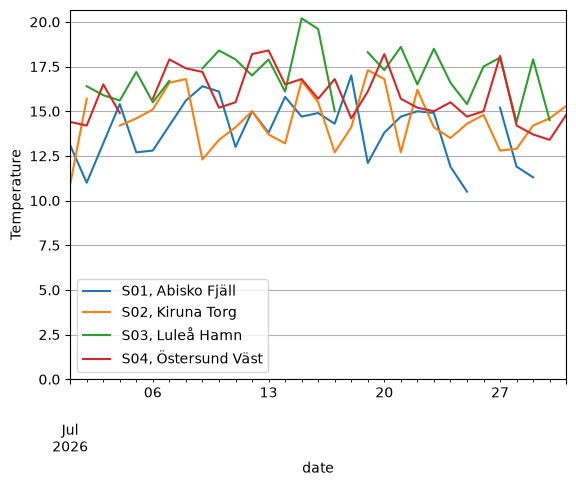

In [173]:
ax = s01_data.plot(x = 'date', y = 'temp', label = 'S01, Abisko Fjäll')
s02_data.plot(x = 'date', y = 'temp', label = 'S02, Kiruna Torg', ax=ax)
s03_data.plot(x = 'date', y = 'temp', label = 'S03, Luleå Hamn', ax=ax)
s04_data.plot(x = 'date', y = 'temp', label = 'S04, Östersund Väst', ax=ax)
plt.ylim(bottom=0)
plt.ylabel('Temperature')
plt.grid(True)
plt.show()


In [174]:
s05_data = readings[readings['station_id'] == 'S05'].sort_values('date')
s06_data = readings[readings['station_id'] == 'S06'].sort_values('date')
s07_data = readings[readings['station_id'] == 'S07'].sort_values('date')
s08_data = readings[readings['station_id'] == 'S08'].sort_values('date')
s05_data['date'] = pd.to_datetime(s05_data['date'])
s06_data['date'] = pd.to_datetime(s06_data['date'])
s07_data['date'] = pd.to_datetime(s07_data['date'])
s08_data['date'] = pd.to_datetime(s08_data['date'])
s07_data['temp'] = (s07_data['temp'] - 32) * 5 / 9

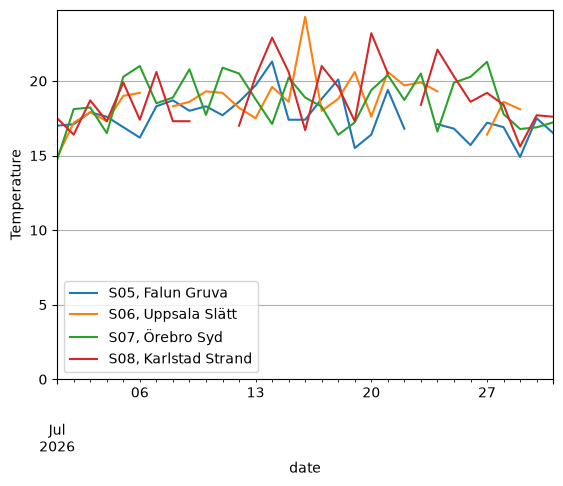

In [175]:
ax2 = s05_data.plot(x = 'date', y = 'temp', label = 'S05, Falun Gruva')
s06_data.plot(x = 'date', y = 'temp', label = 'S06, Uppsala Slätt', ax=ax2)
s07_data.plot(x = 'date', y = 'temp', label = 'S07, Örebro Syd', ax=ax2)
s08_data.plot(x = 'date', y = 'temp', label = 'S08, Karlstad Strand', ax=ax2)
plt.ylim(bottom=0)
plt.ylabel('Temperature')
plt.grid(True)
plt.show()

In [176]:
readings.drop(columns=['raw_station_id'], inplace=True)

In [177]:
readings.head()

,station_id,date,temp,humidity
0,S11,2026-07-27,21.5,78
1,S05,2026-07-17,18.8,66
2,S02,2026-07-22,16.2,79
3,S03,2026-07-14,16.1,66
4,S06,2026-07-03,17.9,53


In [178]:
duplicates = readings[readings.duplicated(subset=['station_id', 'date'], keep=False)]
print(duplicates.sort_values(by=['station_id', 'date']))

    station_id        date  temp  humidity
165        S11  2026-07-01  18.5        73
297        S11  2026-07-01  18.5        73
9          S11  2026-07-02  17.5        52
76         S11  2026-07-02  17.5        52
22         S11  2026-07-03  18.0        76
173        S11  2026-07-03  18.0        76
285        S11  2026-07-04  18.4        73
298        S11  2026-07-04  18.4        73
257        S11  2026-07-05  18.2        64
378        S11  2026-07-05  18.2        64
40         S11  2026-07-06  19.9        71
178        S11  2026-07-06  19.9        71
37         S11  2026-07-07  17.8        72
109        S11  2026-07-07  17.8        72
67         S11  2026-07-08  18.0        64
82         S11  2026-07-08  18.0        64
33         S11  2026-07-09  20.8        76
228        S11  2026-07-09  20.8        76
235        S11  2026-07-10  21.3        58
249        S11  2026-07-10  21.3        58


Super sneaky!!!

In [179]:
print("Rows before:", len(readings))
readings.drop_duplicates(inplace=True)
print("Rows after:", len(readings))

Rows before: 413
Rows after: 403


In [180]:
s13_data = readings[readings['station_id'] == 'S13'].sort_values('date')

In [181]:
print(stations.loc[12])

station_id                          S06
name           Uppsala Slätt (new mast)
region                         Svealand
elevation_m                          27
Name: 12, dtype: object


In [182]:
print(stations.loc[5])

station_id               S06
name           Uppsala Slätt
region              Svealand
elevation_m               25
Name: 5, dtype: object


In [183]:
stations.iloc[5] = stations.iloc[12]

In [184]:
stations.drop(index=12, inplace=True)

In [185]:
stations.head(15)

,station_id,name,region,elevation_m
0,S01,Abisko Fjäll,Norrland,388
1,S02,Kiruna Torg,Norrland,530
2,S03,Luleå Hamn,Norrland,12
3,S04,Östersund Väst,Norrland,376
4,S05,Falun Gruva,Svealand,120
5,S06,Uppsala Slätt (new mast),Svealand,27
6,S07,Örebro Syd,Svealand,55
7,S08,Karlstad Strand,Svealand,48
8,S09,Jönköping Höjd,Götaland,145
9,S10,Kalmar Sund,Götaland,8


In [186]:
print(readings[readings['station_id'] == 'S07'].sort_values('date'))

    station_id        date  temp  humidity
123        S07  2026-07-01  58.5        78
341        S07  2026-07-02  64.6        54
320        S07  2026-07-03  64.8        61
410        S07  2026-07-04  61.7        53
359        S07  2026-07-05  68.5        75
134        S07  2026-07-06  69.8        79
259        S07  2026-07-07  65.3        85
268        S07  2026-07-08  66.0        78
288        S07  2026-07-09  69.4        68
48         S07  2026-07-10  63.9        57
252        S07  2026-07-11  69.6        72
223        S07  2026-07-12  68.9        53
160        S07  2026-07-13  65.8        61
177        S07  2026-07-14  62.8        59
280        S07  2026-07-15  68.4        65
7          S07  2026-07-16  66.0        64
279        S07  2026-07-17  64.9        77
393        S07  2026-07-18  61.5        69
399        S07  2026-07-19  63.0        67
394        S07  2026-07-20  66.9        83
411        S07  2026-07-21  68.7        60
315        S07  2026-07-22  65.7        74
401        

In [187]:

readings.loc[readings['station_id'] == 'S07', 'temp'] = ((readings.loc[readings['station_id'] == 'S07', 'temp'] - 32) * 5 / 9).round(1)

In [188]:
print(readings[readings['station_id'] == 'S07'].sort_values('date'))

    station_id        date  temp  humidity
123        S07  2026-07-01  14.7        78
341        S07  2026-07-02  18.1        54
320        S07  2026-07-03  18.2        61
410        S07  2026-07-04  16.5        53
359        S07  2026-07-05  20.3        75
134        S07  2026-07-06  21.0        79
259        S07  2026-07-07  18.5        85
268        S07  2026-07-08  18.9        78
288        S07  2026-07-09  20.8        68
48         S07  2026-07-10  17.7        57
252        S07  2026-07-11  20.9        72
223        S07  2026-07-12  20.5        53
160        S07  2026-07-13  18.8        61
177        S07  2026-07-14  17.1        59
280        S07  2026-07-15  20.2        65
7          S07  2026-07-16  18.9        64
279        S07  2026-07-17  18.3        77
393        S07  2026-07-18  16.4        69
399        S07  2026-07-19  17.2        67
394        S07  2026-07-20  19.4        83
411        S07  2026-07-21  20.4        60
315        S07  2026-07-22  18.7        74
401        

In [189]:
print("Rows before:", len(readings))
merged_df = pd.merge(readings, stations, on='station_id', how='left')
print("Rows after:", len(merged_df))

Rows before: 403
Rows after: 403


In [190]:
readings.to_csv('cleaned_readings.csv', index=False)

In [191]:
merged_df.head(30)

,station_id,date,temp,humidity,name,region,elevation_m
0,S11,2026-07-27,21.5,78,Lund Park,Götaland,60.0
1,S05,2026-07-17,18.8,66,Falun Gruva,Svealand,120.0
2,S02,2026-07-22,16.2,79,Kiruna Torg,Norrland,530.0
3,S03,2026-07-14,16.1,66,Luleå Hamn,Norrland,12.0
4,S06,2026-07-03,17.9,53,Uppsala Slätt (new mast),Svealand,27.0
5,S09,2026-07-31,14.3,85,Jönköping Höjd,Götaland,145.0
6,S12,2026-07-17,NaN,52,Visby Kust,Götaland,14.0
7,S07,2026-07-16,18.9,64,Örebro Syd,Svealand,55.0
8,S03,2026-07-10,18.4,64,Luleå Hamn,Norrland,12.0
9,S11,2026-07-02,17.5,52,Lund Park,Götaland,60.0


In [192]:
merged_df.to_csv('readings_complete.csv', index=False)